# Subhalo hierarchy of a MW-mass host at $z=0$

Two schematic panels from one SatGen tree at resolution $\psi_{\rm res}=10^{-4}$:

1. **x–y projection**: **every** subhalo alive at $z=0$ (several hundred), drawn by `Tree_Vis.plot_subhalo_projection`. Circle radius = tidal radius, dashed circle = host $R_{\rm vir}$.
2. **graph of the $z=0$ hierarchy**: only the **numbered** subhalos, built with `Arborist.plant_roots` / `water_roots` (`jsm_visualize`).

Only a handful of subhalos are numbered (at most `N_label`). The selection includes at least `min_k2` $k=2$ subhalos and at least `min_k3` $k=3$ subhalos, each with its full chain of hosts, so the graph shows the hierarchy all the way down. Numbers are shared between the two figures: the host is `0`, and the numbered subhalos are `1, 2, …` by $z=0$ mass. Colours come from the **Colours** cell.

**Seed choice.** $k=3$ survivors are rare. Of 23 seeds grown and evolved at $10^{-4}$ (seeds 0–22), only 4 have any $k=3$ subhalo inside the panel: seed 3 (1), seed 7 (3), seed 13 (4) and seed 14 (1). Seed 13 has the most.

In [1]:
import os, sys
import warnings; warnings.simplefilter('ignore')

SATGEN = '/Users/jsmonzon/Research/SatGen'
sys.path.insert(0, f'{SATGEN}/src')
sys.path.insert(0, f'{SATGEN}/mcmc/src')

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.lines import Line2D

import config as cfg
import jsm_SubGen_MW_analog as treegen
import jsm_SubEvo_masscut as subevo
import jsm_visualize as jv

plt.style.use(f'{SATGEN}/notebooks/paper1/paper.mplstyle')
%matplotlib inline

## Colours

**Edit these to change the colour scheme. Both figures read them.**

* `ORDER_COLORS`: one colour per order. The host colour is used for the $R_{\rm vir}$ circle and the host node.
* `CIRCLE_ALPHA`: opacity of the tidal-radius circles in the projection.
* `NUMBERED_ALPHA`: opacity of the numbered subhalos in the projection, higher so they stand out. The graph only shows numbered subhalos, so its nodes use this value.

The graph nodes and legend markers are drawn opaque, so arrows don't show through them. They use `shown_color(k)`, which is `ORDER_COLORS[k]` blended onto the white background at `CIRCLE_ALPHA`. That makes a node look identical to a (non-overlapping) projection circle of the same order. The host is never a filled circle in the projection, so its colour is used unblended.

In [2]:
ORDER_COLORS = {0: '#e41a1c',   # host
                1: '#377eb8',   # k = 1
                2: '#984ea3',   # k = 2
                3: "#ffd000"}   # k = 3
CIRCLE_ALPHA   = 0.3    # opacity of the subhalo circles in the projection
NUMBERED_ALPHA = 0.9    # opacity of the numbered subhalos, so they stand out (graph nodes use it too)
ORDER_NAME   = {0: 'host', 1: '1st order', 2: '2nd order', 3: '3rd order'}

from matplotlib.colors import to_rgb

def order_color(k):
    # base colour of order k (drawn with CIRCLE_ALPHA in the projection)
    return to_rgb(ORDER_COLORS[int(k)])

def shown_color(k, alpha=CIRCLE_ALPHA):
    # opaque colour that looks the same as order_color(k) at `alpha` on white
    if int(k) == 0:
        return order_color(0)
    return tuple(alpha * np.array(order_color(k)) + (1 - alpha))

In [3]:
lgM0       = 12.0    # log10 host mass at z=0 [Msun]
lg_psi_res = -4.0    # log10 tree mass resolution, Mres / M0
seed       = 13

half_main  = 1.2     # projection half-width [Rvir]; only subhalos inside it can be numbered
N_label    = 10      # maximum number of numbered subhalos
min_k2     = 2       # at least this many numbered k=2 subhalos
min_k3     = 1       # at least this many numbered k=3 subhalos
max_host_dist = 50   # [kpc] a numbered k=3 must be at most this far (3D) from its k=2 host

workdir = f'{SATGEN}/notebooks/visualization/schematic'
treedir, figdir = f'{workdir}/trees/', f'{workdir}/figures/'
os.makedirs(treedir, exist_ok=True); os.makedirs(figdir, exist_ok=True)

## Grow and evolve the tree

These are the batch scripts' own `loop` functions. Two details make them work here:

* `treegen.loop` reseeds with `np.random.seed()` (no argument). That call is pinned to `seed` so the tree is reproducible.
* `treegen.loop` leaves `cfg.Mres` set to the tree resolution, and `ev.msub` would then use it as a mass floor during evolution. The batch scripts run in separate processes, so they never see this. Here it is reset to `None` before evolving.

If the evolved file already exists, this cell does nothing.

In [4]:
tag      = f'MW_lgres{lg_psi_res}_s{seed}'
raw_file = f'{treedir}tree_{tag}.npz'
evo_file = f'{treedir}tree_{tag}_evo.npz'

if not os.path.exists(evo_file):    # about 1.5 min at psi_res = 1e-4
    treegen.final_path, treegen.lgM0, treegen.lgMres = treedir, lgM0, lgM0 + lg_psi_res
    cfg.psi_res = 10**lg_psi_res
    _seed = np.random.seed
    np.random.seed = lambda *args: _seed(seed)
    try:
        treegen.loop(tag)
    finally:
        np.random.seed = _seed
    cfg.Mres = None

    np.random.seed(seed)
    subevo.loop(raw_file)

## Load and select

`Tree_Vis` provides the projection and the tidal radii, and `jv.Arborist` provides the per-snapshot hierarchy (`plant_roots` / `water_roots`). Both are `Tree_Reader` subclasses, so one class can inherit from both.

* `shown`: every subhalo alive at $z=0$. All of these are drawn in the projection.
* `numbered`: the subhalos that get a number (at most `N_label`), chosen from those inside the projection panel:
  1. the most massive $k=3$ subhalo(s) within `max_host_dist` of their $k=2$ host, up to `min_k3`, each with its whole chain of hosts ($k=2$ parent, $k=1$ grandparent). The distance cut skips $k=3$ subhalos that are formally still bound to a host but sit hundreds of kpc from it, because they don't illustrate the nesting;
  2. more $k=2$ subhalos, with their hosts, until there are `min_k2`;
  3. the most massive $k=1$ subhalos, to fill up to `N_label`.

  A host is numbered even if it lies outside the panel, so the graph never has a missing link.

`load_and_select(seed)` does all of this for one seed and returns it as a namespace `S`. The figure functions below take `S`, so the same figures can be drawn for any seed (see the last section).

In [5]:
from types import SimpleNamespace

class SchematicTree(jv.Tree_Vis, jv.Arborist):
    pass

def load_and_select(seed):
    # load the evolved tree for `seed`, pick the numbered subhalos and compute tidal radii; returns everything the figures need
    tree = SchematicTree(file=f'{treedir}tree_MW_lgres{lg_psi_res}_s{seed}_evo.npz', verbose=False, mass_threshold=0.0)
    rvir = tree.VirialRadius[0, 0]
    xy   = tree.cartesian_stitched[:, 0, :2]
    X    = tree.cartesian_stitched[:, 0, :3]
    k0   = tree.order[:, 0]

    shown    = np.where(tree.orbit_mask[:, 0])[0]
    in_panel = shown[np.all(np.abs(xy[shown]) < half_main * rvir, axis=1)]
    by_mass  = lambda inds: np.asarray(inds)[np.argsort(tree.mass[inds, 0])[::-1]]

    numbered = []
    def add_chain(ind):                  # a subhalo plus all of its hosts up to (not including) the main host
        while ind != 0 and ind not in numbered:
            numbered.append(ind)
            ind = tree.ParentID[ind, 0]
    n_numbered = lambda k: sum(k0[i] == k for i in numbered)
    near_host  = lambda i: np.linalg.norm(X[i] - X[tree.ParentID[i, 0]]) < max_host_dist

    for k, n_min in ((3, min_k3), (2, min_k2)):
        cands = by_mass(in_panel[k0[in_panel] == k])
        if k == 3:
            cands = [i for i in cands if near_host(i)]
        for ind in cands:
            if n_numbered(k) >= n_min:
                break
            add_chain(ind)
    for ind in by_mass(in_panel[k0[in_panel] == 1]):
        if len(numbered) >= N_label:
            break
        add_chain(ind)

    numbered = by_mass(numbered)
    assert len(numbered) <= N_label, 'the k=2 / k=3 chains alone need more than N_label numbers'
    label = {0: 0} | {ind: n + 1 for n, ind in enumerate(numbered)}   # tree index -> schematic number

    # tidal radii of every shown subhalo; 'shown' is the selection plot_subhalo_projection draws
    mask = np.zeros_like(tree.orbit_mask)
    mask[shown, 0] = True
    tree.regime_masks['shown'] = mask
    rt = tree.compute_tidal_radius(iz=0, mask=mask[:, 0])

    return SimpleNamespace(seed=seed, tree=tree, rvir=rvir, xy=xy, k0=k0, shown=shown, in_panel=in_panel,
                           numbered=numbered, label=label, rt=rt)

def print_summary(S):
    tree, k0, ip = S.tree, S.k0, S.in_panel
    print(f'seed {S.seed}: host M = {tree.mass[0, 0]:.2e} Msun, Rvir = {S.rvir:.0f} kpc')
    print(f'{S.shown.size} subhalos alive at z=0, {ip.size} inside the panel: ' +
          ', '.join(f'{np.sum(k0[ip] == k)} with k={k}' for k in np.unique(k0[ip])))
    print('\n #   k  host   log m   r/Rvir')
    for ind in S.numbered:
        print(f'{S.label[ind]:2d}  {k0[ind]:2d}  {S.label[tree.ParentID[ind, 0]]:>4}  {np.log10(tree.mass[ind, 0]):6.2f}'
              f'  {tree.rmags_stitched[ind, 0] / S.rvir:6.2f}')

S = load_and_select(seed)
print_summary(S)

seed 13: host M = 1.00e+12 Msun, Rvir = 259 kpc
530 subhalos alive at z=0, 458 inside the panel: 361 with k=1, 93 with k=2, 4 with k=3

 #   k  host   log m   r/Rvir
 1   1     0   11.19    0.50
 2   1     0   10.55    0.83
 3   1     0   10.34    0.77
 4   1     0   10.13    0.42
 5   1     0    9.96    1.49
 6   2     1    9.93    0.32
 7   1     0    9.71    0.66
 8   1     0    9.55    0.86
 9   2     1    9.53    0.60
10   3     6    6.70    0.34


## Figure 1: x–y projection

`plot_subhalo_projection` takes its selection from `regime_masks`. `draw_projection` calls it once per order (`'shown_k1'`, `'shown_k2'`, …), so each order is its own layer: higher orders are drawn on top, with 3rd order highest. Within an order, the routine draws the largest circles first, and the numbered subhalos are then drawn above the rest at `NUMBERED_ALPHA` so they stand out. Labels of 1st-order subhalos (and the host `0`) are centred on them. Labels of the orders listed in `label_offset` (2nd and 3rd) are moved off by that many points, with a leader line back to the subhalo; `label_offset_for` overrides the offset for individual numbers. `draw_projection` then restyles the routine's output with the notebook colours:

* it hides the routine's legend;
* it recolours the dashed $R_{\rm vir}$ circle with the host colour;
* it refills the circles with `ORDER_COLORS` at `CIRCLE_ALPHA`;
* it adds a thin black outline (`outline_lw`).

Circles of the orders in `min_radius_orders` are drawn with radius $\max(r_t,$ `min_radius`$)$, 20 kpc by default. Without this floor, most $k=3$ (and many $k=2$) subhalos have $r_t$ of a few kpc and disappear at this scale.

Only the `numbered` subhalos get a label.

* **left**: the whole system out to `half_main` $\times R_{\rm vir}$;
* **right**: a zoom on the $k=1$ host of the numbered $k=2$/$k=3$ subhalos. `zoom_half = None` picks a half-width just large enough to hold that host and its numbered subhalos.

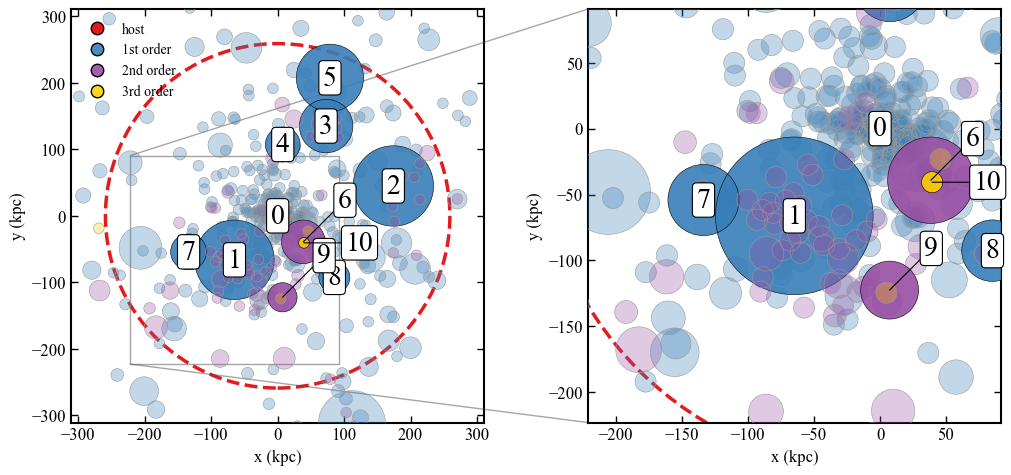

In [6]:
from matplotlib.collections import EllipseCollection

outline_lw   = 0.4         # black outline on every circle [pt]
rvir_lw      = 2.5         # line width of the host's dashed Rvir circle [pt] (the routine's default is 1.2)
grey_rest_edges = True     # switch: outline the non-numbered subhalos in grey instead of black
rest_edgecolor  = '0.6'    # the grey used when grey_rest_edges is on
min_radius   = 8.0        # [kpc] circles of the orders in min_radius_orders are drawn with radius max(r_t, min_radius)
min_radius_orders = (1, 2, 3)   # which orders get the floor, e.g. (3,) to only enlarge the k=3 subhalos
label_offset = {2: (30, 30), 3: (30, 30)}   # order -> label offset [pt] with a leader line; orders not listed are centred on the subhalo
label_offset_for = {10: (40, 0)}   # number -> offset [pt] for exceptions (seed 13: #10 sits 5 kpc from #6, and below-right is #8's label)
zoom_half    = None        # [kpc]; None = fit the zoomed subhalo's numbered group
label_box    = dict(boxstyle='round,pad=0.15', fc='w', ec='k', lw=0.8)   # white box with a black outline behind the numbers (None = no box)
label_zorder = 100         # numbers above every circle layer (order k: rest at 10k, numbered at 10k+2, outlines +1)
legend_zorder = 200        # legend above everything, including the numbers

def draw_projection(a, S, half, only_numbered=False):
    # plot_subhalo_projection once per order, so each order is its own layer (3rd order on top).
    # Within an order, the numbered subhalos are drawn above the rest, at NUMBERED_ALPHA.
    # only_numbered=True: draw just the numbered subhalos (the routine draws them, at NUMBERED_ALPHA).
    r = np.where(np.isin(S.k0, min_radius_orders), np.maximum(S.rt, min_radius), S.rt)
    pool = np.asarray(S.numbered) if only_numbered else S.shown
    is_numbered = np.isin(pool, S.numbered) & (not only_numbered)
    routine_alpha = NUMBERED_ALPHA if only_numbered else CIRCLE_ALPHA

    def circles(inds, z, alpha):
        # filled circles of one order (opaque black outline just above), drawn directly
        d = 2 * r[inds]
        k = S.k0[inds[0]]
        a.add_collection(EllipseCollection(d, d, np.zeros_like(d), units='xy', offsets=S.xy[inds],
                                           offset_transform=a.transData, facecolors=order_color(k),
                                           edgecolors='none', alpha=alpha, zorder=z))
        a.add_collection(EllipseCollection(d, d, np.zeros_like(d), units='xy', offsets=S.xy[inds],
                                           offset_transform=a.transData, facecolors='none',
                                           edgecolors='k', linewidths=outline_lw, zorder=z + 1))

    for k in sorted(set(S.k0[pool])):
        rest = pool[(S.k0[pool] == k) & ~is_numbered]
        mine = pool[(S.k0[pool] == k) & is_numbered]
        if rest.size:                             # the routine draws this order's other subhalos
            mask = np.zeros_like(S.tree.orbit_mask)
            mask[rest, 0] = True
            S.tree.regime_masks[f'shown_k{k}'] = mask
            n_coll = len(a.collections)
            S.tree.plot_subhalo_projection(rt=r, proj='xy', iz=0, regime=f'shown_k{k}', size_mode='physical',
                                           scale=half, alpha=routine_alpha, ax=a)
            routine = a.collections[n_coll]
            routine.set_facecolor(order_color(k))
            routine.set_edgecolor('none')
            routine.set_zorder(10 * k)
            d = 2 * r[rest]
            edge = rest_edgecolor if (grey_rest_edges and not only_numbered) else 'k'
            a.add_collection(EllipseCollection(d, d, np.zeros_like(d), units='xy', offsets=S.xy[rest],
                                               offset_transform=a.transData, facecolors='none',
                                               edgecolors=edge, linewidths=outline_lw, zorder=10 * k + 1))
        if mine.size:                             # numbered subhalos of this order, on top of the rest
            circles(mine, 10 * k + 2, NUMBERED_ALPHA)
    a.set_title('')
    for art in a.get_children():                  # the routine adds a legend on every call: hide them all
        if isinstance(art, plt.matplotlib.legend.Legend):
            art.set_visible(False)
    rvir_circles = [p for p in a.patches if isinstance(p, plt.Circle) and np.isclose(p.radius, S.rvir)]
    rvir_circles[0].set_edgecolor(order_color(0))   # the routine's black dashed Rvir circle -> host colour
    rvir_circles[0].set_linewidth(rvir_lw)
    for p in rvir_circles[1:]:                    # one per call; keep a single one
        p.remove()

def label_inside(a, S, fontsize=20):
    # number the host (0, at the centre) and the numbered subhalos whose centre is inside the panel
    (x0, x1), (y0, y1) = a.get_xlim(), a.get_ylim()
    if x0 < 0 < x1 and y0 < 0 < y1:
        a.text(0, 0, '0', ha='center', va='center', fontsize=fontsize, bbox=label_box, zorder=label_zorder)
    for ind in S.numbered:
        x, y = S.xy[ind]
        if not (x0 < x < x1 and y0 < y < y1):
            continue
        offset = label_offset_for.get(S.label[ind], label_offset.get(S.k0[ind]))
        if offset is None:                        # centred on the subhalo
            a.text(x, y, str(S.label[ind]), ha='center', va='center', fontsize=fontsize, bbox=label_box,
                   zorder=label_zorder)
        else:                                     # moved off the subhalo, with a leader line back to it
            a.annotate(str(S.label[ind]), xy=(x, y), xytext=offset, textcoords='offset points',
                       ha='center', va='center', fontsize=fontsize, bbox=label_box, zorder=label_zorder,
                       arrowprops=dict(arrowstyle='-', color='k', lw=0.8, shrinkA=0, shrinkB=0))

def order_legend(a, S, **kw):
    handles = [Line2D([], [], marker='o', ls='', ms=9, mfc=shown_color(k, NUMBERED_ALPHA), mec='k', label=ORDER_NAME[k])
               for k in sorted({0} | set(S.k0[S.shown]))]
    a.legend(handles=handles, **kw).set_zorder(legend_zorder)

fig, (ax, axz) = plt.subplots(1, 2, figsize=(12, 7), gridspec_kw={'wspace': 0.25})
for a in (ax, axz):
    draw_projection(a, S, half_main)

# zoom panel: centred on the k=1 subhalo that hosts numbered subhalos
zi = [i for i in S.numbered if S.k0[i] == 1 and any(S.tree.ParentID[j, 0] == i for j in S.numbered)][0]
c  = S.xy[zi]
zh = zoom_half
if zh is None:
    P = S.tree.ParentID[:, 0]
    group = [i for i in S.numbered if zi in (i, P[i], P[P[i]])]
    zh = 1.15 * max(np.max(np.abs(S.xy[i] - c)) + max(S.rt[i], min_radius) for i in group)
axz.set_xlim(c[0] - zh, c[0] + zh); axz.set_ylim(c[1] - zh, c[1] + zh)
ax.indicate_inset_zoom(axz, edgecolor='0.3')

for a in (ax, axz):
    label_inside(a, S, fontsize=20)

order_legend(ax, S, loc='upper left', fontsize=10, frameon=False)

# fig.savefig(f'{figdir}hierarchy_xy_projection_z0_psi4.pdf', bbox_inches='tight')
plt.show()

## Figure 1b: x–y projection, full view only

The left panel of Figure 1 on its own, without the zoom. It uses the same helpers and the same `half_main`.

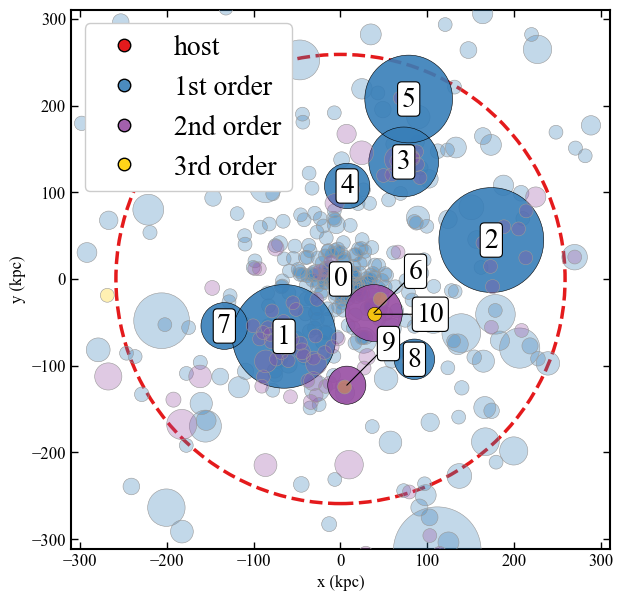

In [7]:
fig, ax = plt.subplots(figsize=(7, 7))
draw_projection(ax, S, half_main)
label_inside(ax, S, fontsize=20)
order_legend(ax, S, loc='upper left', fontsize=20, frameon=True, framealpha=1)

# fig.savefig(f'{figdir}hierarchy_xy_projection_z0_full_psi4.pdf', bbox_inches='tight')
plt.show()

## Figure 1c: x–y projection, numbered subhalos only

The same view as Figure 1b, showing only the numbered subhalos (`draw_projection(..., only_numbered=True)`).

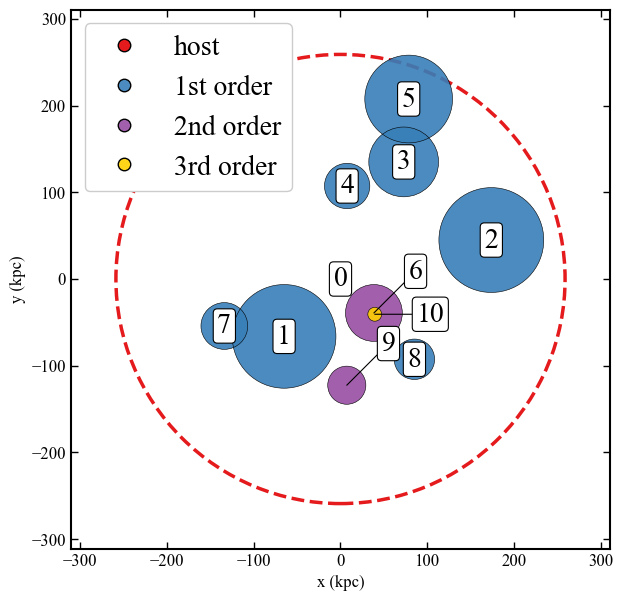

In [8]:
fig, ax = plt.subplots(figsize=(7, 7))
draw_projection(ax, S, half_main, only_numbered=True)
label_inside(ax, S, fontsize=20)
order_legend(ax, S, loc='upper left', fontsize=20, frameon=True, framealpha=1)

# fig.savefig(f'{figdir}hierarchy_xy_projection_z0_numbered_psi4.pdf', bbox_inches='tight')
plt.show()

## Figure 2: graph of the $z=0$ hierarchy

`plant_roots` / `water_roots` build a treelib hierarchy for every snapshot, and `tree.forest[0]` is the one at $z=0$. It is restricted to the numbered subhalos. Their hosts are always numbered too (see the selection), so every edge is a real host link. Arrows point from each subhalo to its host.

The layout is horizontal. The host is at the centre. A $k=1$ subhalo that has subhalos of its own (a "hub") sits on the right, and its subhalos fan out further right. A $k=3$ subhalo sits one more step to the right of its $k=2$ host. The other $k=1$ subhalos fill an arc on the left. The layout parameters are at the top of the cell.

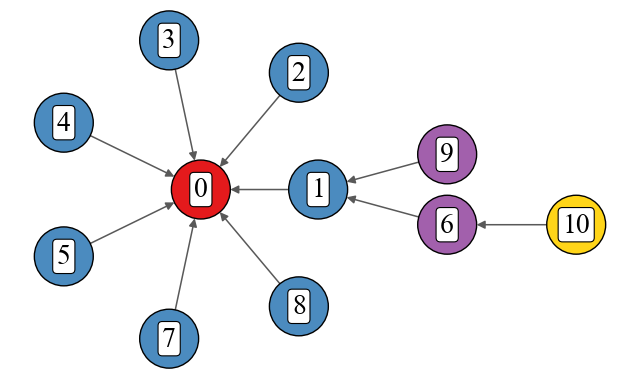

In [9]:
hub_spread = 25          # deg, half-range of hub angles around +x
arc        = 50          # deg, the left arc runs from +arc to 360 - arc
r_arc      = 1.3         # radius of the left arc (hubs sit at radius 1)
kid_dx, kid_dy = 1.1, 0.6    # step right / vertical spacing of a hub's subhalos (spaced for node_size)
node_size  = 1800        # node area [pt^2]; the labels sit in label_box (from the projection cell) on top

def draw_graph(S, ax):
    # graph of the numbered subhalos at z=0; returns the networkx graph
    S.tree.plant_roots()
    S.tree.water_roots()
    z0 = S.tree.forest[0]

    def shown_parent(ind):
        p = int(z0.parent(str(ind)).identifier)
        return p if p in S.label else shown_parent(p)

    G = nx.DiGraph()
    G.add_node(0, k=0)
    for ind in S.numbered:
        G.add_node(S.label[ind], k=int(S.k0[ind]))
    for ind in S.numbered:
        G.add_edge(S.label[ind], S.label[shown_parent(ind)])

    k1   = [n for n in G if G.nodes[n]['k'] == 1]
    hubs = [n for n in k1 if G.in_degree(n) > 0]
    rest = [n for n in k1 if G.in_degree(n) == 0]

    pos = {0: np.zeros(2)}
    for a, n in zip(np.radians(np.linspace(-hub_spread, hub_spread, len(hubs)) if len(hubs) > 1 else [0.0]), hubs):
        pos[n] = np.array([np.cos(a), np.sin(a)])
    for a, n in zip(np.radians(np.linspace(arc, 360 - arc, len(rest))), rest):
        pos[n] = r_arc * np.array([np.cos(a), np.sin(a)])

    def place_kids(n, dy):
        kids = sorted(G.predecessors(n))
        for i, c in enumerate(kids):
            pos[c] = pos[n] + np.array([kid_dx, dy * (i - (len(kids) - 1) / 2)])
            place_kids(c, dy / 2)
    for n in hubs:
        place_kids(n, kid_dy)

    nx.draw_networkx_edges(G, pos, ax=ax, node_size=node_size, edge_color='0.35', width=1.1,
                           arrows=True, arrowstyle='-|>', arrowsize=12)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=node_size, edgecolors='k', linewidths=1,
                           node_color=[shown_color(G.nodes[n]['k'], NUMBERED_ALPHA) for n in G])
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=20, font_color='k', bbox=label_box,
                            font_family=plt.rcParams['font.family'])
    ax.set_aspect('equal'); ax.axis('off')
    return G

fig, ax = plt.subplots(figsize=(8, 5))
G = draw_graph(S, ax)

handles = [Line2D([], [], marker='o', ls='', ms=9, mfc=shown_color(k), mec='k', label=ORDER_NAME[k])
           for k in sorted({G.nodes[n]['k'] for n in G})]
# ax.legend(handles=handles, loc='upper left', fontsize=10, frameon=False)

# fig.savefig(f'{figdir}hierarchy_graph_z0_psi4.pdf', bbox_inches='tight')
plt.show()

## All qualifying seeds

These are the $\psi_{\rm res}=10^{-4}$ seeds with at least one $k=3$ subhalo inside the panel (from the scan of seeds 0–22). Each seed gets the full-view projection (as in Figure 1b) and the graph, drawn with the same functions and settings as above. Nothing is saved here.

In [10]:
# qualifying_seeds = [3, 7, 13, 14]

# for s in qualifying_seeds:
#     Ss = load_and_select(s)
#     print_summary(Ss)

#     fig, ax = plt.subplots(figsize=(7, 7))
#     draw_projection(ax, Ss, half_main)
#     label_inside(ax, Ss, fontsize=20)
#     order_legend(ax, Ss, loc='upper left', fontsize=20, frameon=True, framealpha=1)
#     ax.set_title(f'seed {s}')
#     plt.show()

#     fig, ax = plt.subplots(figsize=(8, 5))
#     draw_graph(Ss, ax)
#     ax.set_title(f'seed {s}')
#     plt.show()